# 04 - Signal Generation: Z-Score, Entry/Exit, Stop-Loss

Turns the Kalman spread and regime gate into a position signal. Thresholds are picked up front as hypotheses, not tuned against backtest results afterward - that's a subtle way to leak look-ahead bias in through the researcher rather than the model.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "../data"

with open(f"{DATA_DIR}/kalman_config.json") as f:
    kconfig = json.load(f)

fx = pd.read_parquet(f"{DATA_DIR}/kalman_fx.parquet").iloc[kconfig["burn_in"]:]
comm = pd.read_parquet(f"{DATA_DIR}/kalman_comm.parquet").iloc[kconfig["burn_in"]:]
regime_fx = pd.read_parquet(f"{DATA_DIR}/regime_fx.parquet")
regime_comm = pd.read_parquet(f"{DATA_DIR}/regime_comm.parquet")

def prep(df, regime):
    # inner join aligns to the regime series' index (which starts later, after its own
    # feature/rolling-window and HMM warm-up), then drop the HMM's warm-up NaNs explicitly
    return df.join(regime, how="inner").dropna(subset=["calm_prob"])

fx_m = prep(fx, regime_fx)
comm_m = prep(comm, regime_comm)

print("FX:", fx_m.index.min().date(), "->", fx_m.index.max().date(), fx_m.shape)
print("Commodities:", comm_m.index.min().date(), "->", comm_m.index.max().date(), comm_m.shape)

FX: 2015-03-27 -> 2024-08-14 (2446, 8)
Commodities: 2008-11-06 -> 2024-08-14 (3914, 8)


## Z-score of the Kalman spread

The spread is already close to mean-zero, but its volatility still moves around over time, so a rolling z-score keeps the entry/exit thresholds meaningful across periods rather than fixed in raw units.

20 trading days (~1 month) is picked up front - short enough to track the spread's own adaptivity, long enough not to be dominated by one or two outlier days. Shown next to 10-day and 60-day alternatives just to show the sensitivity, not to pick whichever looks best later.

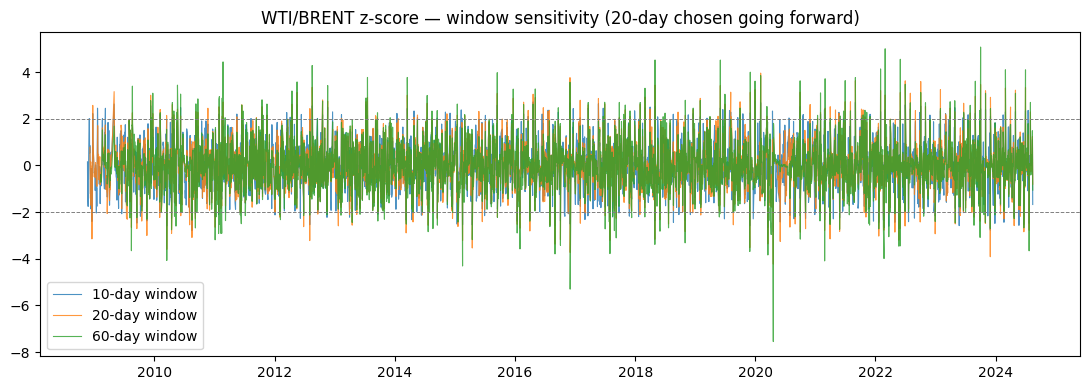

(2427, 9) (3895, 9)


In [2]:
def compute_zscore(spread, window):
    mu = spread.rolling(window).mean()
    sd = spread.rolling(window).std()
    return (spread - mu) / sd

fig, ax = plt.subplots(figsize=(11, 4))
for w, color in zip([10, 20, 60], ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    z = compute_zscore(comm_m["kalman_spread"], w)
    ax.plot(z.index, z, label=f"{w}-day window", linewidth=0.8, alpha=0.8)
ax.axhline(2, color="grey", linestyle="--", linewidth=0.7)
ax.axhline(-2, color="grey", linestyle="--", linewidth=0.7)
ax.set_title("WTI/BRENT z-score — window sensitivity (20-day chosen going forward)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/04_zscore_window_sensitivity.png", dpi=120)
plt.show()

Z_WINDOW = 20
fx_m = fx_m.copy()
fx_m["z"] = compute_zscore(fx_m["kalman_spread"], Z_WINDOW)
comm_m = comm_m.copy()
comm_m["z"] = compute_zscore(comm_m["kalman_spread"], Z_WINDOW)

fx_m = fx_m.dropna(subset=["z"])
comm_m = comm_m.dropna(subset=["z"])
print(fx_m.shape, comm_m.shape)

## Entry, exit, stop-loss

| Rule | Value | Purpose |
|---|---|---|
| Entry | \|z\| > 2.0, only while the regime gate says "calm" | standard 2-sigma entry, restricted to HMM-classified mean-reverting periods |
| Exit (reversion) | \|z\| < 0.5 | take profit once the spread's mostly reverted |
| Stop-loss | \|z\| > 4.0 for 5 consecutive days | if it keeps diverging instead of reverting, treat the relationship as broken and exit regardless of P&L |
| Max holding period | 60 trading days | backstop against a position that never triggers either exit |

The calm-regime requirement only gates new entries, not exits - an open position isn't force-closed the moment the regime label flips. Notebook 03 showed the raw daily regime probability is noisy even though the underlying regime tends to persist for days-to-weeks, so exiting on every flip would whipsaw the strategy. Risk on open positions is instead handled by the stop-loss and max-holding rules, which react to the spread itself.

In [3]:
ENTRY_Z, EXIT_Z, STOP_Z, STOP_CONSEC_DAYS, MAX_HOLD, REGIME_THRESH = 2.0, 0.5, 4.0, 5, 60, 0.5

def build_signals(df, entry_z=ENTRY_Z, exit_z=EXIT_Z, stop_z=STOP_Z,
                   stop_consec=STOP_CONSEC_DAYS, max_hold=MAX_HOLD, regime_thresh=REGIME_THRESH):
    n = len(df)
    z = df["z"].values
    calm = df["calm_prob"].values > regime_thresh

    position = np.zeros(n, dtype=int)
    exit_reason = np.array([""] * n, dtype=object)

    pos, hold_days, stop_streak = 0, 0, 0
    for t in range(n):
        if pos == 0:
            stop_streak, hold_days = 0, 0
            if calm[t]:
                if z[t] > entry_z:
                    pos = -1  # spread too high -> short the spread
                elif z[t] < -entry_z:
                    pos = 1   # spread too low -> long the spread
        else:
            hold_days += 1
            stop_streak = stop_streak + 1 if abs(z[t]) > stop_z else 0

            if stop_streak >= stop_consec:
                pos, exit_reason[t] = 0, "stop_loss_divergence"
            elif hold_days >= max_hold:
                pos, exit_reason[t] = 0, "max_holding_period"
            elif abs(z[t]) < exit_z:
                pos, exit_reason[t] = 0, "z_reverted"

        position[t] = pos

    out = df.copy()
    out["position"], out["exit_reason"] = position, exit_reason
    return out

fx_sig = build_signals(fx_m)
comm_sig = build_signals(comm_m)

def count_trades(pos):
    return int(((pos.shift(1).fillna(0) == 0) & (pos != 0)).sum())

for label, sig in [("AUD/NZD", fx_sig), ("WTI/BRENT", comm_sig)]:
    n_trades = count_trades(sig["position"])
    pct_in_position = (sig["position"] != 0).mean() * 100
    exit_counts = sig.loc[sig["exit_reason"] != "", "exit_reason"].value_counts().to_dict()
    print(f"{label}: {n_trades} trades, {pct_in_position:.1f}% of days in a position, exits={exit_counts}")

AUD/NZD: 84 trades, 10.0% of days in a position, exits={'z_reverted': 84}
WTI/BRENT: 138 trades, 10.4% of days in a position, exits={'z_reverted': 138}


The stop-loss and max-holding rules rarely or never trigger in this data - nearly every trade exits via ordinary z-reversion, which fits how strongly stationary the Kalman spread tested in notebooks 01-02. They stay in as risk backstops even though this sample didn't need them much.

## Signal detail on a sample window

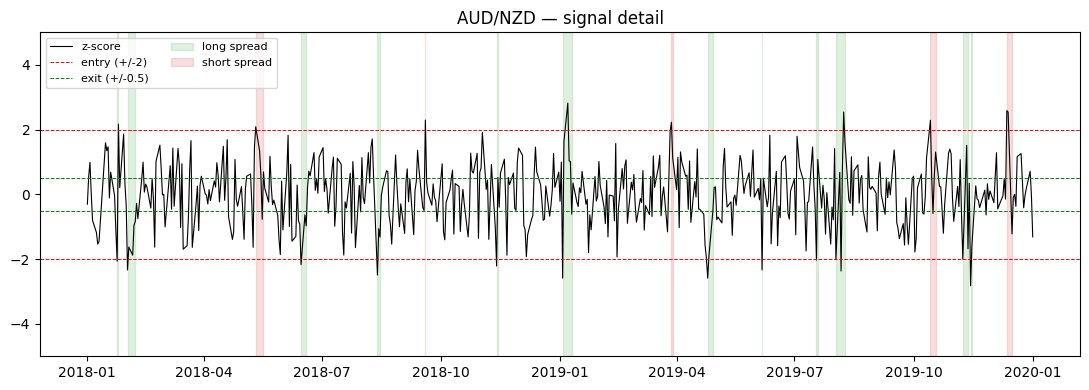

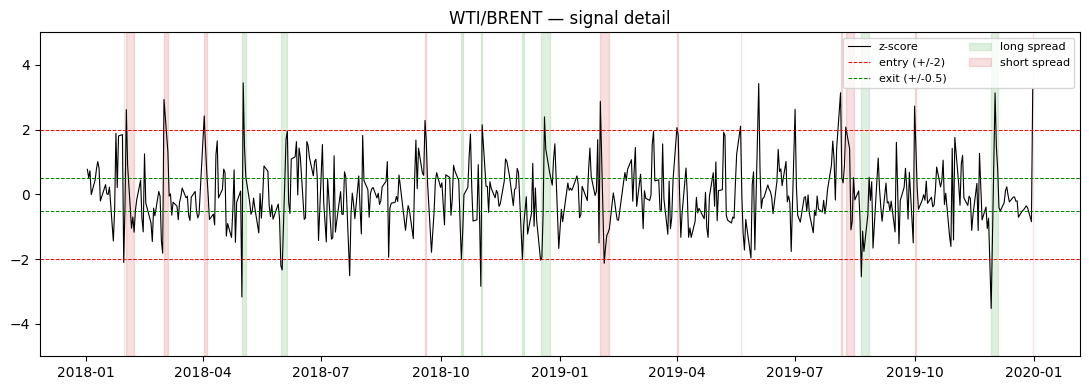

In [4]:
def plot_signal(df, label, start, end, fname):
    window = df.loc[start:end]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(window.index, window["z"], color="black", linewidth=0.8, label="z-score")
    ax.axhline(ENTRY_Z, color="red", linestyle="--", linewidth=0.7, label="entry (+/-2)")
    ax.axhline(-ENTRY_Z, color="red", linestyle="--", linewidth=0.7)
    ax.axhline(EXIT_Z, color="green", linestyle="--", linewidth=0.7, label="exit (+/-0.5)")
    ax.axhline(-EXIT_Z, color="green", linestyle="--", linewidth=0.7)
    ax.fill_between(window.index, -5, 5, where=(window["position"] == 1), color="#2ca02c", alpha=0.15, label="long spread")
    ax.fill_between(window.index, -5, 5, where=(window["position"] == -1), color="#d62728", alpha=0.15, label="short spread")
    ax.set_ylim(-5, 5)
    ax.set_title(f"{label} - signal detail")
    ax.legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig(f"{DATA_DIR}/{fname}", dpi=120)
    plt.show()

plot_signal(fx_sig, "AUD/NZD", "2018-01-01", "2020-01-01", "04_signal_detail_fx.png")
plot_signal(comm_sig, "WTI/BRENT", "2018-01-01", "2020-01-01", "04_signal_detail_comm.png")

## Save

In [5]:
fx_sig.to_parquet(f"{DATA_DIR}/signals_fx.parquet")
comm_sig.to_parquet(f"{DATA_DIR}/signals_comm.parquet")

signal_config = {
    "z_window": Z_WINDOW, "entry_z": ENTRY_Z, "exit_z": EXIT_Z, "stop_z": STOP_Z,
    "stop_consec_days": STOP_CONSEC_DAYS, "max_hold": MAX_HOLD, "regime_thresh": REGIME_THRESH,
}
with open(f"{DATA_DIR}/signal_config.json", "w") as f:
    json.dump(signal_config, f, indent=2)

print("Saved signals_fx.parquet, signals_comm.parquet, signal_config.json to", DATA_DIR)

Saved signals_fx.parquet, signals_comm.parquet, signal_config.json to ../data


Notebook 05 turns `position` into trades. Entries/exits execute at the *next* day's price relative to the signal date - deciding on today's close is fine, trading on it isn't.